## K-Nearest Neighbors

The K-Nearest Neighbors (KNN) is one of the simplest machine learning algorithms that can be used for both regression and classification. KNN is a lazy learning algorithm and doesn’t technically train a model to make predictions. Instead an observation is predicted to be the class of that of the largest proportion of the k nearest observations. KNN method is a direct attempt at approximating the conditional expectation using actual data.

For **regression**, the predicted value is the mean of the K neighbors and the estimator is given as

In [1]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs\KNN for Stock Prediction"

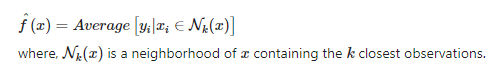

In [2]:
Image.open(os.path.join(dir_path,'KNN_regression.PNG'))

For **classification**, the predicted label is the class with the plurality, i.e., which class is most represented among the neighbors. This is equivlent to taking a majority vote among the 
knearest neighbors. For each class j=1,⋯,K, we then compute the empirical (conditional) probability

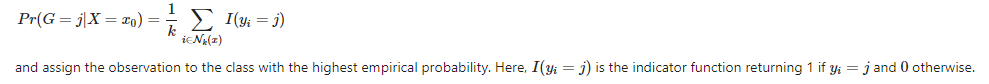

In [3]:
Image.open(os.path.join(dir_path,'KNN_classification.PNG'))

### The Three Steps

The popularity of KNN comes from the fact that it is very easy to understand and interpret. It’s accuracy is often comparable or even better than more complicated algorithms. Once, k is specified, finding nearest neighbors is a 3-step process.

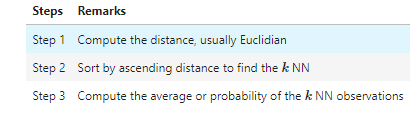

In [4]:
Image.open(os.path.join(dir_path,'KNN_steps.PNG'))

### Finding the neighbors

Intuitively, distance can be thought of as a measure of similarity. Euclidean distance is the most commonly used but other distance metrics such as Manhattan work as well. The generalized distance metric is called the Minkowski distance, defined as

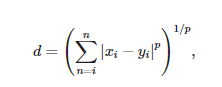

In [5]:
Image.open(os.path.join(dir_path,'KNN_neighbour.PNG'))

where xi and yi are the two observations for which distance dis being calculated with a hyperparameter, integer p.

When p=1, the Minkowski distance is the Manhattan distance and when p=2, the Minkowski distance is the just the standard Euclidean distance. With the K neighbors identified using distance metrics, the algorithm can make a classification or prediction with the label values of the neighbors.

### KNN Model

KNN is a non-parametric method and it does not assume any function as there are no parameters to be estimated. The selection of the number of neighbors k is done using the training set. Selecting k close to 1 gives the most flexibility (low bias), but also has the highest variability (high variance) while on the other hand, selecting a large k gives the least flexibility (high bias), but also has the lowest variability (low variance). In particular,  k = N will assign all new test observations to a single class. The best way of selecting k is through cross validation. Another alternative approach is to employ the popular Elbow method to select k.

## Workflow

In [ ]:
Image.open(os.path.join(dir_path,'ML_workflow.PNG'))

### Import Libraries : Exhaustive list, not all being used

In [33]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# Self organizing maps(SOM)
from minisom import MiniSom

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Shapley values, used in DTEM
import shap

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

## Data Collection

In [7]:
df = pd.read_csv(os.path.join(dir_path,'spy.csv'),parse_dates = True, index_col=0)  # parse_dates - to covert to datetime object

## EDA (Exploratory Data Analysis)

In [8]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,5114.0000,5114.0000,5114.0000,5114.0000,5114.0000,5114.0000
mean,159.8580,160.7984,158.8300,159.8609,136.3339,112759338.8150
std,60.6795,60.8303,60.5159,60.6941,67.9237,98704855.3978
min,67.9500,70.0000,67.1000,68.1100,54.1844,1436600.0000
25%,115.7525,116.6625,114.9025,115.8975,87.4125,48212550.0000
50%,137.0850,137.9550,136.1100,136.9450,106.4888,83575450.0000
75%,201.7675,202.7875,200.7225,201.8725,182.9516,151554375.0000
max,337.7900,339.0800,337.4800,338.3400,336.3621,871026300.0000


## Cleaning and Imputation

In [9]:
df.isnull().sum()

Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

## Feature Specification

Features or Predictors are also known as an independent variable which are used to determine the value of the target variable. We will derive a features set from the original dataset.

In [10]:
df['O-C'] = df['Open'] - df['Close']
df['H-L'] = df['High'] - df['Low']

In [11]:
X = df.loc[:,['O-C','H-L']]

## Target or Label Definition

Label or the target variable is also known as the dependent variable. Here, the target variable is whether Nifty Index price will close up or down on the next trading day. If the tomorrow’s closing price is greater than the 0.995 of today's closing price, then we will buy the Nifty, else we will sell the index.

We assign a value of +1 for the buy signal and -1 for the sell signal to target variable. The target can be described as :

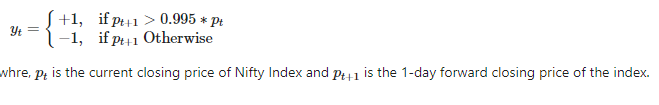

In [12]:
Image.open(os.path.join(dir_path,'Target.PNG'))

In [14]:
# try to take labels as 0,1 in line with scikit learn package

y = np.where(df['Adj Close'].shift(periods = -1) > 0.995*df['Adj Close'],1,-1)

In [15]:
# highly skewed data - class imbalance  
pd.Series(y).value_counts()

 1    3885
-1    1229
dtype: int64

## Model Pre-Implementation and Implementation

### Split Data

In [19]:
# Splitting the datasets into training and testing data.
# Always keep shuffle = False for financial time series

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.2, shuffle=False,random_state=0)

Since the KNN model calculates distances, the dataset needs to be scaled for the model to work properly. All the features should have a similar scale. The scaling can be accomplished by using the MinMaxScaler transformer.


In [20]:
#---------------------------------------------------------------------------------------------------------------
# Initialize the model --> Pipeline --> fit() --> predict()
#---------------------------------------------------------------------------------------------------------------

#---------------------------------------------------------------------------------------------------------------
# Hyperparameters :n_neighbors
#---------------------------------------------------------------------------------------------------------------

# pipeline - Sequentially apply a list of transforms and a final estimator.Intermediate steps of the pipeline must be 
# 'transforms', that is, they must implement `fit` and `transform` methods.
# transformer ~ scaler, estimator ~ regressor/classifiers

# Pipleine contains both model pre-implementation and model implementation(initialize the model)
model = Pipeline([('scaler',MinMaxScaler()),('classifier',KNeighborsClassifier())])   # Pipeline() - gives model object
model.fit(X_train,y_train)                                                            # model.fit()
y_pred = model.predict(X_test)                                                        # model.predict()

## Model Attributes

In [21]:
# shows classes and probabilities assigned to them
# class assigment based on probability- results will be same as model.predict()

y_pred_prob = model.predict_proba(X_train)                                           # model.predict_prob()
model.classes_                                                                       # model.classes_
model.get_params                                                                     # model.get_params

array([-1,  1])

## Prediction Quality

### Accuracy Score

In [22]:
acc_train = accuracy_score(y_train,model.predict(X_train))                           # accuracy_score()
acc_test = accuracy_score(y_test,y_pred)
acc_train, acc_test

(0.7802493277927157, 0.7497556207233627)

**Accuracy on testing set is lower thar training set - Probelm of Overfitting -- Go for Tuned Model with resampling method**

### Confusion Matrix

Confusion matrix is a table used to describe the performance of a classification model on a set of test data for which the true values are known.

|Outcome|Position|
|:-|:-|
|True Negative|upper-left|
|False Negative|lower-left|
|False Positive|upper-right|
|True Positive|lower-right|

**True Positive** is an outcome where the model correctly predicts the positive class. Similarly, a true negative is an outcome where the model correctly predicts the negative class.
**False Positive** is an outcome where the model incorrectly predicts the positive class. And a false negative is an outcome where the model incorrectly predicts the negative class.

Note: In a binary classification task, the terms ‘positive’ and ‘negative’ refer to the classifier’s prediction, and the terms ’true’ and ‘false’ refer to whether that prediction corresponds to the external judgment (sometimes known as the ‘observation’) and the axes can be flipped. Refer  [Scikit-Learn Binary Classification](https://scikit-learn.org/stable/modules/model_evaluation.html#binary-classification) for further details.

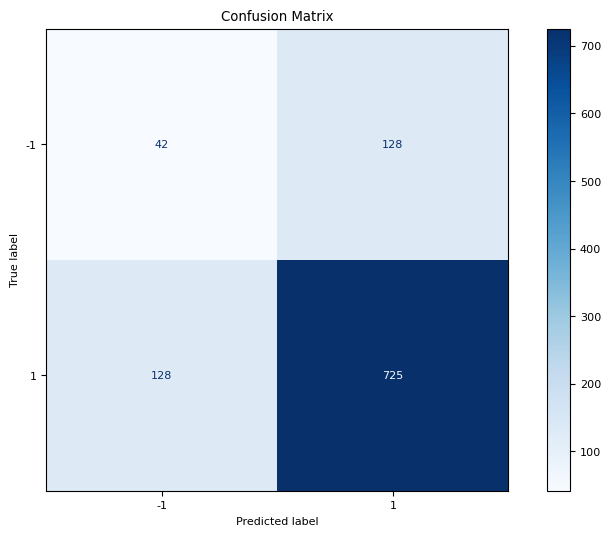

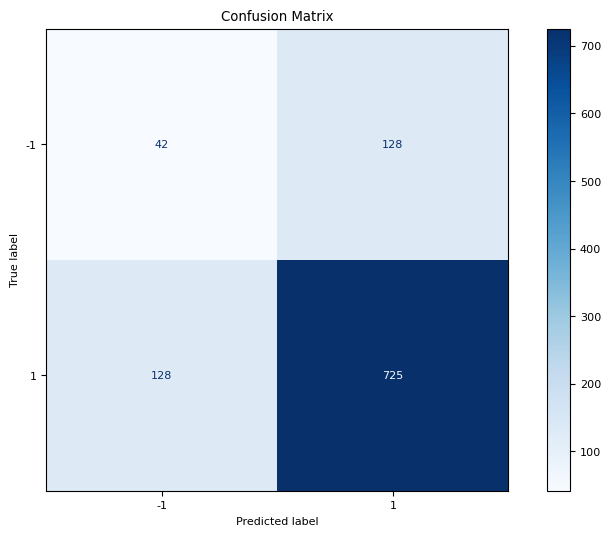

In [23]:
confusion_matrix(y_test, y_pred)           # confusion_matrix()

# both are same

# ConfusionMatrixDisplay.from_estimator()
disp = ConfusionMatrixDisplay.from_estimator(estimator = model, X= X_test, y= y_test,labels =model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# OR

# ConfusionMatrixDisplay.from_predictor()
disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels =model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

### Classification Report

In [24]:
# Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          -1       0.25      0.25      0.25       170
           1       0.85      0.85      0.85       853

    accuracy                           0.75      1023
   macro avg       0.55      0.55      0.55      1023
weighted avg       0.75      0.75      0.75      1023



**Macro Average**
Average of precision (or recall or f1-score) of different classes.

**Weighted Average**
Actual Class1 instance * precision (or recall or f1-score) of Class1 + Actual Class2 instance * (or recall or f1-score) of Class2.

### Receiver Operator Characterisitc Curve (ROC)

The area under the ROC curve (AUC) is a measure of how well a model can distinguish between two classes. The ROC curve is created by plotting the true positive rate (TPR) against the false positive rate (FPR) at various classification thresholds.

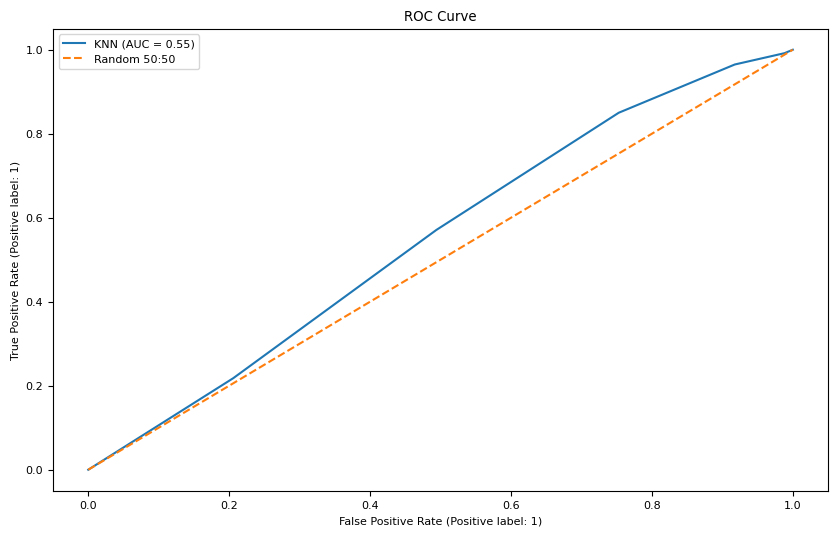

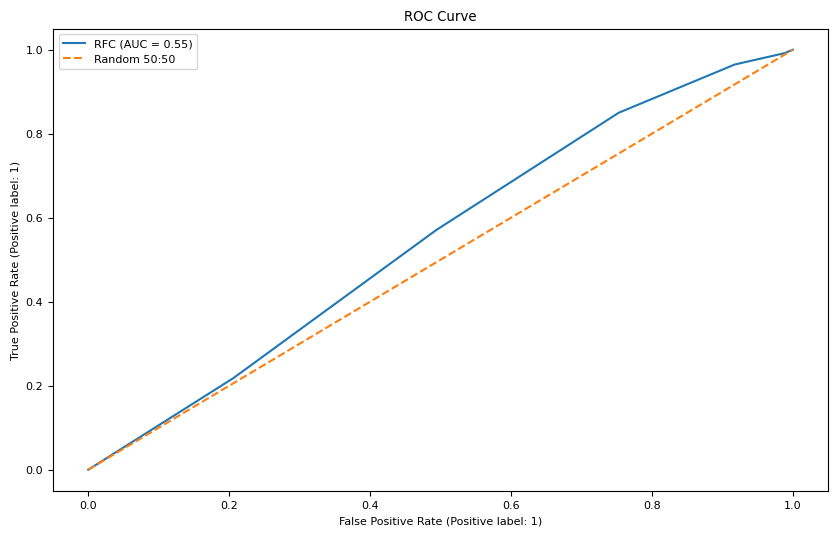

In [32]:
RocCurveDisplay.from_estimator(estimator = model, X= X_test, y= y_test, name ='KNN')   # RocCurveDisplay.from_estimator()
plt.plot([0,1],[0,1],linestyle = '--',label = 'Random 50:50')
plt.title('ROC Curve')
plt.legend()
plt.show()

# OR
# The ROC curve uses the decision function. To get the same result, one needs to call decision_function() or predict_proba()

model_y_pred_proba = model.predict_proba(X_test)                                       # rfc.predict_proba()
model_y_pred_proba_positive = model_y_pred_proba[:, 1] 
RocCurveDisplay.from_predictions(y_test,model_y_pred_proba_positive, name ='RFC')      # RocCurveDisplay.from_predictions()
plt.plot([0,1],[0,1],linestyle = '--',label = 'Random 50:50')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [41]:
roc_curve(y_test,y_pred)

(array([0.        , 0.75294118, 1.        ]),
 array([0.        , 0.84994138, 1.        ]),
 array([ 2,  1, -1]))

## Hyper-parameter Tuning

**Hyper-parameters are parameters that are not directly learnt within estimators. In scikit-learn they are passed as arguments to the constructor of the estimator classes**. It is possible and recommended to search the hyper-parameter space for the best cross validation score. Any parameter provided when constructing an estimator may be optimized in this manner.

### Cross-validation of Time Series

**Time series data are sequential in nature and are characterised by the correlation between observations**. Classical cross-validation techniques such as KFold assume the samples are independent and identically distributed, and would result in poor estimates when applied on time series data.

To preserve the order and have training set occur prior to the test set, we use Forward Chaining method in which the model is initially trained and tested with the same windows size. And, for each subsequent fold, the training window increases in size, encompassing both the previous training data and test data. The new test window once again follows the training window but stays the same length.

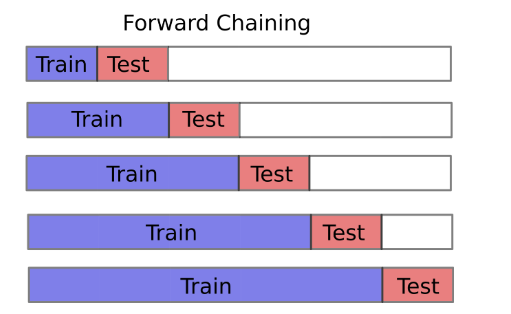

In [34]:
Image.open(os.path.join(dir_path,'Forward_chaining.PNG'))

We will tune the hyperparameters to select the K-Best Neighbor by TimeSeriesSplit from scikit-learn. This is a forward chaining cross-validation method and is a variation from the K Fold. In the kth split, it returns first k folds as train set and the (k+1)th fold as test set. Unlike standard cross-validation methods, successive training sets are supersets of those that come before them

In [ ]:
# TimeSeriesSplit() - Provides train/test indices to split time series data samples

tscv = TimeSeriesSplit(n_splits=5,gap=1)               # TimeSeriesSplit() - gap parameter 1 to avoid data leakage/overlapping

for train, test in tscv.split(X):
    print(train, test)


In [36]:
tscv = TimeSeriesSplit(n_splits=5,gap=1)

### GridSearch

The conventional way of performing hyperparameter optimization has been a grid search (aka parameter sweep). It is an exhaustive search through a manually specified subset of the hyperparameter space of a learning algorithm. A grid search algorithm must be guided by some performance metric, typically measured by cross-validation on the training set or evaluation on a validation set.

GridSearch performs exhaustive search over specified parameter values for an estimator. It implements a “fit” and a “score” method among other methods. The parameters of the estimator used to apply these methods are optimized by cross-validated grid-search over a parameter grid.

In [37]:
model.get_params()                # model.get_params()

{'memory': None,
 'steps': [('scaler', MinMaxScaler()), ('classifier', KNeighborsClassifier())],
 'verbose': False,
 'scaler': MinMaxScaler(),
 'classifier': KNeighborsClassifier(),
 'scaler__clip': False,
 'scaler__copy': True,
 'scaler__feature_range': (0, 1),
 'classifier__algorithm': 'auto',
 'classifier__leaf_size': 30,
 'classifier__metric': 'minkowski',
 'classifier__metric_params': None,
 'classifier__n_jobs': None,
 'classifier__n_neighbors': 5,
 'classifier__p': 2,
 'classifier__weights': 'uniform'}

In [38]:
param_grid = {'classifier__n_neighbors':np.arange(1,51)}                   

# Exhaustive search over specified parameter values for an estimator-create gridsearch object(i.e. simiar to pipeline object)
# 

grid_search = GridSearchCV(estimator = model,               # GridSearchCV()
                           param_grid = param_grid,
                           scoring = 'roc_auc',
                           n_jobs = -1,                     # n_jobs - use all cores avaialble to machine
                           cv = tscv,
                           verbose =1)


In [39]:
grid_search.fit(X_train, y_train)    # grid_search.fit()

Fitting 5 folds for each of 50 candidates, totalling 250 fits


GridSearchCV(cv=TimeSeriesSplit(gap=1, max_train_size=None, n_splits=5, test_size=None),
             estimator=Pipeline(steps=[('scaler', MinMaxScaler()),
                                       ('classifier', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50])},
             scoring='roc_auc', verbose=1)

In [40]:
# Cross validation score
score = cross_val_score(estimator= model,X = X_train,y=y_train,cv = tscv,scoring = None)      # cross_val_score()
print(score)
score = cross_val_score(estimator= model,X = X_train,y=y_train,cv = tscv,scoring='accuracy')
print(score)
score = cross_val_score(estimator= model,X = X_train,y=y_train,cv = tscv,scoring='f1')
print(score)
score = cross_val_score(estimator= model,X = X_train,y=y_train,cv = tscv,scoring='precision')
print(score)
score = cross_val_score(estimator= model,X = X_train,y=y_train,cv = tscv,scoring='roc_auc')
print(score)

[0.60646109 0.71806167 0.6328928  0.72687225 0.71071953]
[0.60646109 0.71806167 0.6328928  0.72687225 0.71071953]
[0.73092369 0.82918149 0.75775194 0.83510638 0.82457703]
[0.74590164 0.8020654  0.70323741 0.79159664 0.79690189]
[0.51284079 0.5263632  0.51410637 0.540287   0.50594653]


In [42]:
print('optimal neighbours is {}'.format(grid_search.best_params_['classifier__n_neighbors']))  # grid_search.best_params_

# this is same as cross_val_score with scoring = 'roc_auc'
print('best score is {}'.format(grid_search.best_score_))                                      # grid_search.best_score_

optimal neighbours is 18
best score is 0.5363688882350791


## Optimal Model

In [43]:
#model = Pipeline([('scaler',MinMaxScaler()),('classifier',KNeighborsClassifier(n_neighbors = grid_search.best_params_['classifier__n_neighbors']))])   
model = KNeighborsClassifier(n_neighbors = grid_search.best_params_['classifier__n_neighbors'])

model.fit(X_train,y_train)                                                           # model.fit()
y_pred = model.predict(X_test)                                                       # model.predict()

# shows classes and probabilities assigned to them
y_pred_prob = model.predict_proba(X_train)                                           # model.predict_prob()
model.classes_                                                                       # model.classes_


array([-1,  1])

### Accuracy Score

In [44]:
acc_train = accuracy_score(y_train,model.predict(X_train))                           # accuracy_score()
acc_test = accuracy_score(y_test,y_pred)
acc_train, acc_test

(0.7472500611097531, 0.7859237536656891)

### Confusion Matrix

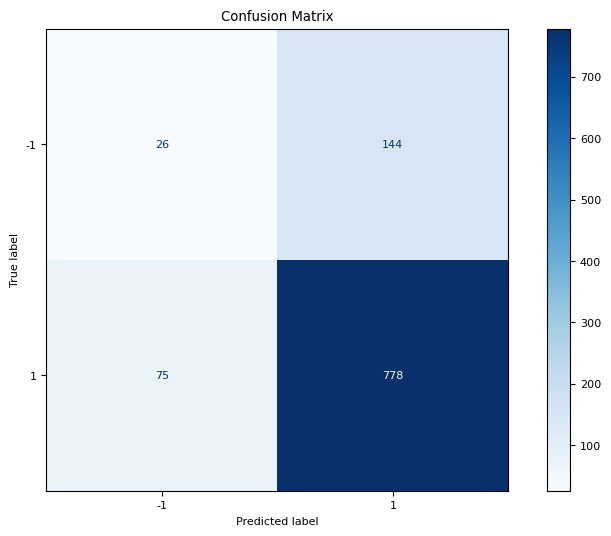

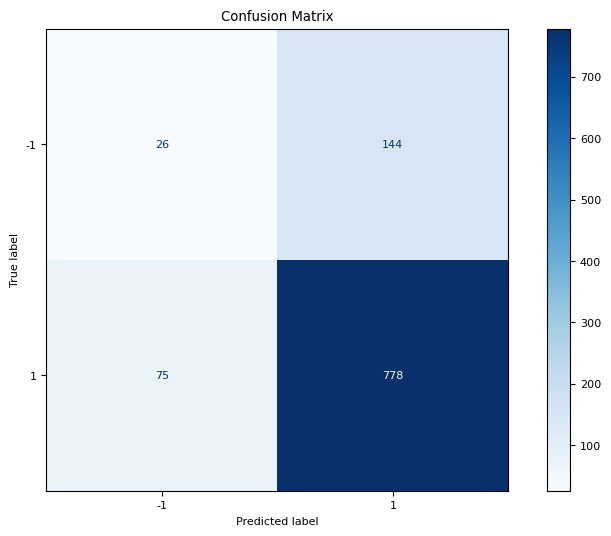

In [45]:
confusion_matrix(y_test, y_pred)           # confusion_matrix()

# ConfusionMatrixDisplay.from_estimator()
disp = ConfusionMatrixDisplay.from_estimator(estimator = model,             # ConfusionMatrixDisplay.from_estimator()
                                             X= X_test, y= y_test,
                                             labels =model.classes_ ,
                                             cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# ConfusionMatrixDisplay.from_predictor()
disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                               labels=model.classes_ ,      # ConfusionMatrixDisplay.from_predictions()
                                               cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

### Classification Report

In [46]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          -1       0.26      0.15      0.19       170
           1       0.84      0.91      0.88       853

    accuracy                           0.79      1023
   macro avg       0.55      0.53      0.53      1023
weighted avg       0.75      0.79      0.76      1023



### ROC Curve

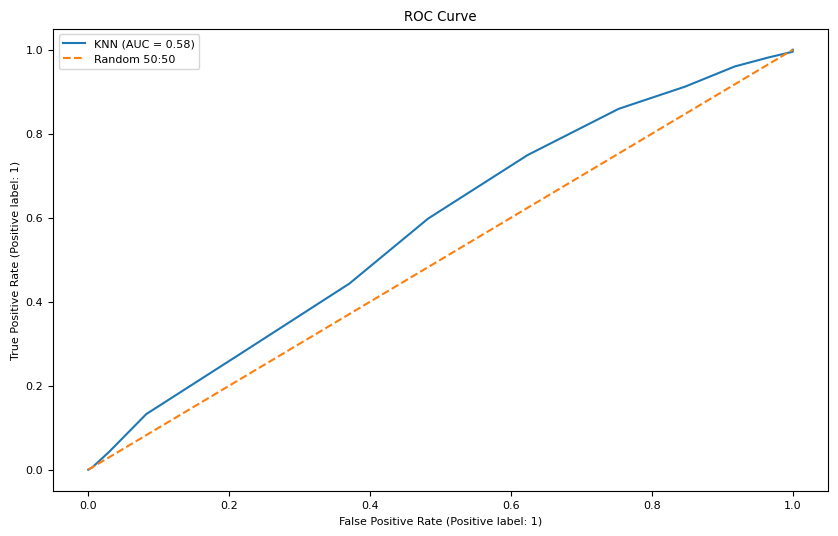

In [48]:
RocCurveDisplay.from_estimator(estimator = model, X= X_test, y= y_test, name ='KNN')
plt.plot([0,1],[0,1],linestyle = '--',label = 'Random 50:50')
plt.title('ROC Curve')
plt.legend()
plt.show()

**Observation**

- Test accuracy improved more than 5% as compared to the earlier model.
- Recall for Class +1 improved by more than 10% as compared to the earlier model while recall for Class -1 decreased by 40%.
- Model improved predictor for upside when compared to the downside.
- Class imbalance skews the prediction and needs to be addressed.

## Trading Strategy

In [49]:
df1 = df.copy(deep = True)

In [50]:
df1['Signal'] = model.predict(X)
df1['Return'] = np.log(df1['Adj Close']).diff(periods = 1).fillna(0)
df1['Strategy'] = df1['Return']*(df1['Signal'].shift(1)).fillna(0)

In [52]:
import pyfolio as pf

In [ ]:
# Localize index for pyfolio
df1.index = df1.index.tz_localize('utc')
pf.create_returns_tear_sheet(df1['Strategy'], live_start_date='2016-04-07')    # create_returns_tear_sheet()

## References


[Time Series Split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)

[Cross Validation](https://scikit-learn.org/stable/modules/cross_validation.html)

[Grid Search CV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

[Hyperparameters Tuning](https://scikit-learn.org/stable/modules/grid_search.html#grid-search)

[K Neighbours Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)